In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

In [ ]:
import os, re

DATA_DIR = "data"

def read_pvgis_csv(path):
    with open(path, encoding="utf-8", errors="ignore") as f:
        lines = f.read().splitlines()
    meta = {}
    for line in lines[:15]:
        for key in ["Latitude", "Longitude", "Elevation"]:
            if line.startswith(key):
                meta[key] = float(re.findall(r"-?\d+\.?\d*", line.split(":", 1)[1])[0])
    start = next(i for i, l in enumerate(lines) if l.startswith("time,"))
    end = start + 1
    while end < len(lines) and lines[end][:1].isdigit():
        end += 1
    header = lines[start].split(",")
    rows = [l.split(",") for l in lines[start + 1:end]]
    d = pd.DataFrame(rows, columns=header)
    d["time"] = pd.to_datetime(d["time"], format="%Y%m%d:%H%M", utc=True)
    for c in d.columns[1:]:
        d[c] = d[c].astype(float)
    d["town"] = os.path.splitext(os.path.basename(path))[0]
    d["lat"], d["lon"], d["elevation"] = meta["Latitude"], meta["Longitude"], meta["Elevation"]
    return d

frames = []
for file in sorted(os.listdir(DATA_DIR)):
    if file.endswith(".csv"):
        d = read_pvgis_csv(os.path.join(DATA_DIR, file))
        frames.append(d)
        print(d["town"][0], "ok", len(d), "| has P:", "P" in d.columns)

raw = pd.concat(frames, ignore_index=True)
print("total rows:", len(raw))
print()
print("missing values per town:")
print(raw.isna().groupby(raw["town"]).sum())    

ALMASNA3 ok 17520 | has P: False
ANJAR ok 17520 | has P: False
BEKAA ok 17520 | has P: False
Beirut-RaficHaririAirport ok 17520 | has P: False
FARAYA ok 17520 | has P: False
HAZMIEH ok 17520 | has P: False
JEZZIN ok 17520 | has P: False
KASLIK ok 17520 | has P: False
PortOfBeirut ok 17520 | has P: False
PortOfTripoli ok 17520 | has P: False
ReneMouawad-Airport ok 17520 | has P: False
baalbek ok 17520 | has P: True
bcharre ok 17520 | has P: True
beirut ok 17520 | has P: True
debbieh ok 17520 | has P: True
halba ok 17520 | has P: True
jbeil ok 17520 | has P: True
mountlebanon ok 17520 | has P: True
nabatieh ok 17520 | has P: True
saida ok 17520 | has P: True
tripoli ok 17520 | has P: True
tyre ok 17520 | has P: True
zahle ok 17520 | has P: True
total rows: 402960

missing values per town:
                           time  G(i)  H_sun  T2m  WS10m  Int  town  lat  lon  \
town                                                                            
ALMASNA3                      0     0   

In [3]:
print(raw.groupby("town")[["lat", "lon", "elevation"]].first())
print()
print("missing values:", raw.isna().sum().sum())
print()
print(raw.describe().round(2))

                              lat     lon  elevation
town                                                
ALMASNA3                   33.705  35.918     1003.0
ANJAR                      33.728  35.932      921.0
BEKAA                      33.675  35.833      867.0
Beirut-RaficHaririAirport  33.823  35.492        6.0
FARAYA                     34.026  35.838     1635.0
HAZMIEH                    33.854  35.537       92.0
JEZZIN                     33.544  35.584      938.0
KASLIK                     33.983  35.619       38.0
PortOfBeirut               33.906  35.534        1.0
PortOfTripoli              34.451  35.828        1.0
ReneMouawad-Airport        34.590  36.013        6.0
baalbek                    34.010  36.212     1172.0
bcharre                    34.252  36.042     1909.0
beirut                     33.896  35.478       64.0
debbieh                    33.666  35.487      461.0
halba                      34.544  36.078      127.0
jbeil                      34.127  35.822     

In [4]:
df = raw.drop(columns=["Int"]).rename(columns={"G(i)": "G"})
df = df[df["G"] > 0].reset_index(drop=True)

df["power_frac"] = df["P"] / 1000

solar_hour = (df["time"].dt.hour + df["time"].dt.minute / 60 + df["lon"] / 15) % 24
doy = df["time"].dt.dayofyear

df["hour_sin"] = np.sin(2 * np.pi * solar_hour / 24)
df["hour_cos"] = np.cos(2 * np.pi * solar_hour / 24)
df["doy_sin"] = np.sin(2 * np.pi * doy / 365)
df["doy_cos"] = np.cos(2 * np.pi * doy / 365)

decl = np.radians(23.44) * np.sin(2 * np.pi * (284 + doy) / 365)
hour_angle = np.radians(15 * (solar_hour - 12))
lat_r = np.radians(df["lat"])
df["sun_elev"] = np.degrees(np.arcsin(
    np.sin(lat_r) * np.sin(decl) + np.cos(lat_r) * np.cos(decl) * np.cos(hour_angle)))

print("daytime rows:", len(df))
print("sun elevation, mine vs PVGIS, mean difference:",
      round((df["sun_elev"] - df["H_sun"]).abs().mean(), 2), "degrees")
df.head()

daytime rows: 199227
sun elevation, mine vs PVGIS, mean difference: 1.03 degrees


,time,G,H_sun,T2m,WS10m,town,lat,lon,elevation,P,power_frac,hour_sin,hour_cos,doy_sin,doy_cos,sun_elev
0,2022-01-01 05:09:00+00:00,7.32,4.33,4.22,1.45,ALMASNA3,33.705,35.918,1003.0,NaN,NaN,0.919355,-0.393429,0.017213,0.999852,4.843440
1,2022-01-01 06:09:00+00:00,107.04,14.40,4.94,1.24,ALMASNA3,33.705,35.918,1003.0,NaN,NaN,0.786202,-0.617969,0.017213,0.999852,14.855278
2,2022-01-01 07:09:00+00:00,226.49,22.97,7.43,1.17,ALMASNA3,33.705,35.918,1003.0,NaN,NaN,0.599471,-0.800397,0.017213,0.999852,23.333003
3,2022-01-01 08:09:00+00:00,133.30,29.36,8.44,1.38,ALMASNA3,33.705,35.918,1003.0,NaN,NaN,0.371886,-0.928278,0.017213,0.999852,29.603925
4,2022-01-01 09:09:00+00:00,282.98,32.83,9.33,1.31,ALMASNA3,33.705,35.918,1003.0,NaN,NaN,0.118959,-0.992899,0.017213,0.999852,32.921247


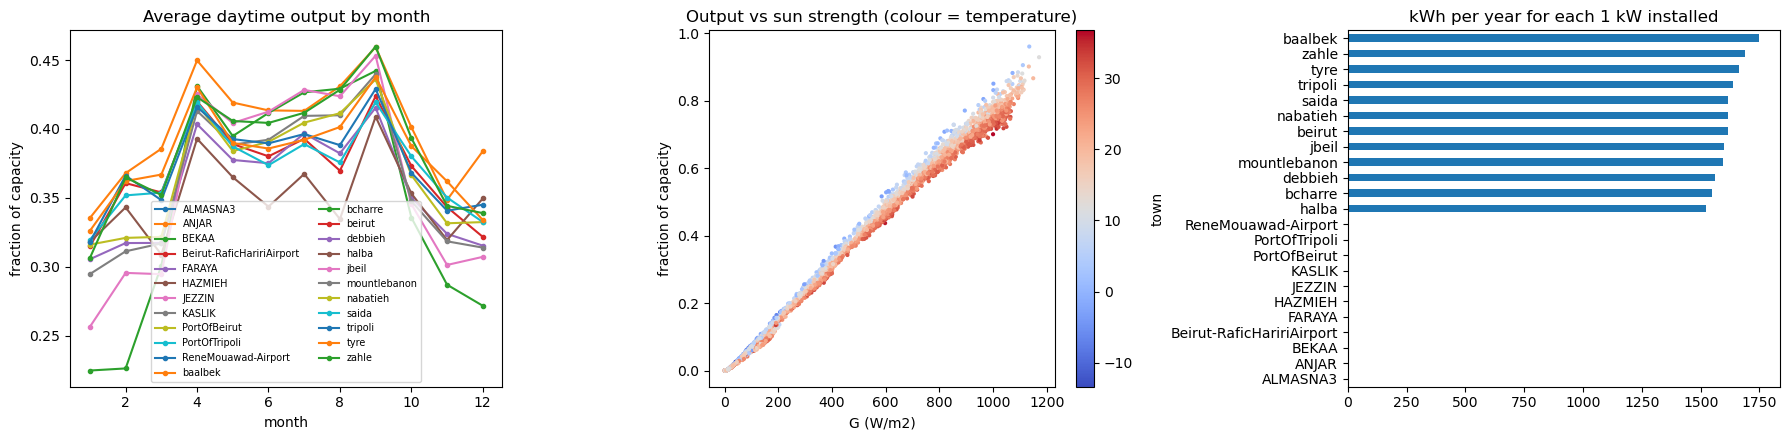

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))

monthly = df.assign(month=df["time"].dt.month).groupby(["month", "town"])["power_frac"].mean().unstack()
monthly.plot(ax=ax[0], marker="o", ms=3)
ax[0].set_title("Average daytime output by month")
ax[0].set_ylabel("fraction of capacity")
ax[0].legend(fontsize=7, ncol=2)

s = df.sample(6000, random_state=0)
sc = ax[1].scatter(s["G"], s["power_frac"], c=s["T2m"], s=4, cmap="coolwarm")
ax[1].set_xlabel("G (W/m2)")
ax[1].set_ylabel("fraction of capacity")
ax[1].set_title("Output vs sun strength (colour = temperature)")
plt.colorbar(sc, ax=ax[1])

yearly = df.groupby("town")["P"].sum() / 1000 / 2
yearly.sort_values().plot.barh(ax=ax[2])
ax[2].set_title("kWh per year for each 1 kW installed")

plt.tight_layout()
plt.show()

In [6]:
FEATURES = ["G", "T2m", "WS10m", "sun_elev", "hour_sin", "hour_cos",
            "doy_sin", "doy_cos", "lat", "lon", "elevation"]
TARGET = "power_frac"
TEST_TOWNS = ["saida", "mountlebanon", "baalbek"]

is_test = df["town"].isin(TEST_TOWNS)
train = df[~is_test].reset_index(drop=True)
test = df[is_test].reset_index(drop=True)

X_train = train[FEATURES].values
y_train = train[TARGET].values
X_test = test[FEATURES].values
y_test = test[TARGET].values

print("train:", X_train.shape, "towns:", sorted(train["town"].unique()))
print("test: ", X_test.shape, "towns:", sorted(test["town"].unique()))

train: (173244, 11) towns: ['ALMASNA3', 'ANJAR', 'BEKAA', 'Beirut-RaficHaririAirport', 'FARAYA', 'HAZMIEH', 'JEZZIN', 'KASLIK', 'PortOfBeirut', 'PortOfTripoli', 'ReneMouawad-Airport', 'bcharre', 'beirut', 'debbieh', 'halba', 'jbeil', 'nabatieh', 'tripoli', 'tyre', 'zahle']
test:  (25983, 11) towns: ['baalbek', 'mountlebanon', 'saida']


In [7]:
mu = X_train.mean(axis=0)
sd = X_train.std(axis=0)
X_train_s = (X_train - mu) / sd
X_test_s = (X_test - mu) / sd

def mae(y, p):
    return np.mean(np.abs(y - p))

def rmse(y, p):
    return np.sqrt(np.mean((y - p) ** 2))

def r2(y, p):
    return 1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2)

print("train means after scaling:", X_train_s.mean(axis=0).round(3))
print("train stds after scaling: ", X_train_s.std(axis=0).round(3))

baseline = np.full(len(y_test), y_train.mean())
print("baseline -> MAE:", round(mae(y_test, baseline), 4),
      "| RMSE:", round(rmse(y_test, baseline), 4),
      "| R2:", round(r2(y_test, baseline), 4))

train means after scaling: [ 0. -0.  0. -0. -0.  0.  0.  0.  0.  0.  0.]
train stds after scaling:  [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
baseline -> MAE: nan | RMSE: nan | R2: nan


My Linear Regression -> MAE: nan | RMSE: nan | R2: nan


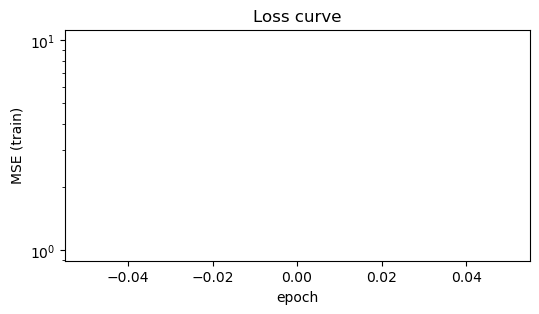

In [8]:
class MyLinearRegression:
    def __init__(self, lr=0.1, epochs=5000):
        self.lr = lr
        self.epochs = epochs

    def fit(self, X, y):
        n, d = X.shape
        self.w = np.zeros(d)
        self.b = 0.0
        self.history = []
        for epoch in range(self.epochs):
            y_hat = X @ self.w + self.b
            err = y_hat - y
            self.history.append(np.mean(err ** 2))
            grad_w = (2 / n) * (X.T @ err)
            grad_b = (2 / n) * err.sum()
            self.w -= self.lr * grad_w
            self.b -= self.lr * grad_b
        return self

    def predict(self, X):
        return X @ self.w + self.b


my_lr = MyLinearRegression().fit(X_train_s, y_train)
p = my_lr.predict(X_test_s)

print("My Linear Regression -> MAE:", round(mae(y_test, p), 4),
      "| RMSE:", round(rmse(y_test, p), 4),
      "| R2:", round(r2(y_test, p), 4))

plt.figure(figsize=(6, 3))
plt.plot(my_lr.history)
plt.yscale("log")
plt.xlabel("epoch")
plt.ylabel("MSE (train)")
plt.title("Loss curve")
plt.show()

In [9]:
from sklearn.linear_model import LinearRegression

Xb = np.column_stack([X_train_s, np.ones(len(X_train_s))])
theta = np.linalg.solve(Xb.T @ Xb, Xb.T @ y_train)

sk_lr = LinearRegression().fit(X_train_s, y_train)

check = pd.DataFrame({
    "gradient descent (mine)": np.append(my_lr.w, my_lr.b),
    "normal equation (mine)": theta,
    "sklearn": np.append(sk_lr.coef_, sk_lr.intercept_),
}, index=FEATURES + ["bias"])
print(check.round(4))
print()

Xb_test = np.column_stack([X_test_s, np.ones(len(X_test_s))])
print("test RMSE -> gradient descent:", round(rmse(y_test, my_lr.predict(X_test_s)), 5),
      "| normal equation:", round(rmse(y_test, Xb_test @ theta), 5),
      "| sklearn:", round(rmse(y_test, sk_lr.predict(X_test_s)), 5))

ValueError: Input y contains NaN.

In [ ]:
print(raw.groupby("town").size())
print(raw["P"].isna().groupby(raw["town"]).sum())

In [ ]:
import time
from sklearn.neighbors import KNeighborsRegressor

class MyKNN:
    def __init__(self, k=10, batch=200):
        self.k = k
        self.batch = batch

    def fit(self, X, y):
        self.X = X
        self.y = y
        self.sq = (X ** 2).sum(axis=1)
        return self

    def predict(self, X):
        out = np.empty(len(X))
        for s in range(0, len(X), self.batch):
            B = X[s:s + self.batch]
            d2 = (B ** 2).sum(axis=1)[:, None] + self.sq[None, :] - 2 * B @ self.X.T
            nearest = np.argpartition(d2, self.k, axis=1)[:, :self.k]
            out[s:s + self.batch] = self.y[nearest].mean(axis=1)
        return out


t0 = time.time()
my_knn = MyKNN(k=10).fit(X_train_s, y_train)
p_knn = my_knn.predict(X_test_s)
print("time:", round(time.time() - t0, 1), "seconds")

print("My KNN -> MAE:", round(mae(y_test, p_knn), 4),
      "| RMSE:", round(rmse(y_test, p_knn), 4),
      "| R2:", round(r2(y_test, p_knn), 4))

sk_knn = KNeighborsRegressor(n_neighbors=10).fit(X_train_s, y_train)
idx = np.random.default_rng(0).choice(len(X_test_s), 1000, replace=False)
print("mean |mine - sklearn| on 1000 test rows:",
      round(np.abs(p_knn[idx] - sk_knn.predict(X_test_s[idx])).mean(), 6))

time: 31.0 seconds
My KNN -> MAE: 0.019 | RMSE: 0.0275 | R2: 0.9895
mean |mine - sklearn| on 1000 test rows: 0.0


In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

models = {
    "Decision Tree": DecisionTreeRegressor(max_depth=10, min_samples_leaf=20, random_state=0),
    "Random Forest": RandomForestRegressor(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=0),
    "Gradient Boosting": HistGradientBoostingRegressor(random_state=0),
}

preds = {
    "Baseline (mean)": baseline,
    "Linear Regression (mine)": my_lr.predict(X_test_s),
    "KNN (mine)": p_knn,
}

for name, m in models.items():
    t0 = time.time()
    m.fit(X_train_s, y_train)
    preds[name] = m.predict(X_test_s)
    print(name, "trained in", round(time.time() - t0, 1), "seconds")

rows = []
for name, p in preds.items():
    p = np.clip(p, 0, None)
    row = {"model": name, "MAE": mae(y_test, p), "RMSE": rmse(y_test, p), "R2": r2(y_test, p)}
    for town in TEST_TOWNS:
        mask = (test["town"] == town).values
        row[f"MAE {town}"] = mae(y_test[mask], p[mask])
    rows.append(row)

results = pd.DataFrame(rows).set_index("model").sort_values("RMSE")
results.round(4)

Decision Tree trained in 0.5 seconds
Random Forest trained in 7.9 seconds


C:\Users\tarek\.anaconda\anacondanew\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\tarek\.anaconda\anacondanew\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\tarek\.anaconda\anacondanew\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\tarek\.anaconda\anacondanew\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, clos

Gradient Boosting trained in 1.4 seconds


,MAE,RMSE,R2,MAE saida,MAE mountlebanon,MAE baalbek
model,,,,,,
Gradient Boosting,0.0018,0.0025,0.9999,0.0017,0.0016,0.0020
Random Forest,0.0015,0.0026,0.9999,0.0012,0.0012,0.0021
Decision Tree,0.0044,0.0065,0.9994,0.0040,0.0039,0.0053
Linear Regression (mine),0.0100,0.0127,0.9978,0.0086,0.0095,0.0119
KNN (mine),0.0190,0.0275,0.9895,0.0178,0.0187,0.0205
Baseline (mean),0.2412,0.2689,-0.0017,0.2342,0.2369,0.2525


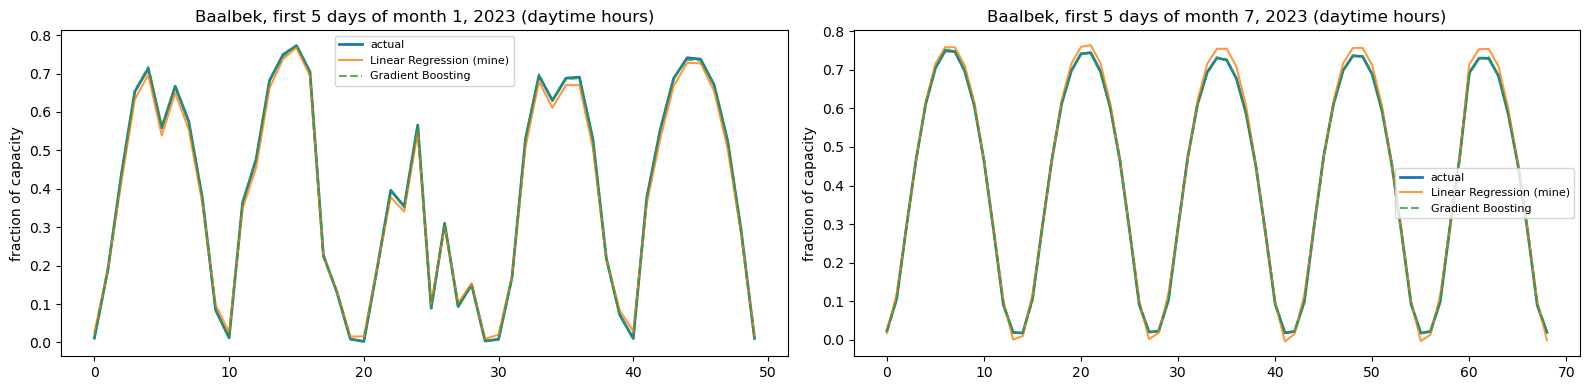

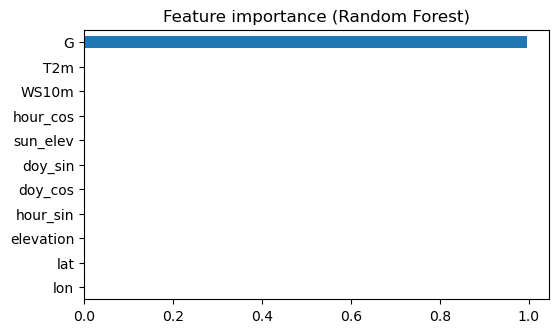

In [ ]:
best = models["Gradient Boosting"]
p_best = np.clip(best.predict(X_test_s), 0, None)
p_lr = my_lr.predict(X_test_s)

fig, ax = plt.subplots(1, 2, figsize=(16, 4))
for a, month in zip(ax, [1, 7]):
    w = test[(test["town"] == "baalbek") & (test["time"].dt.year == 2023)
             & (test["time"].dt.month == month) & (test["time"].dt.day <= 5)].index
    a.plot(y_test[w], label="actual", linewidth=2)
    a.plot(p_lr[w], label="Linear Regression (mine)", alpha=0.8)
    a.plot(p_best[w], label="Gradient Boosting", alpha=0.8, linestyle="--")
    a.set_title(f"Baalbek, first 5 days of month {month}, 2023 (daytime hours)")
    a.set_ylabel("fraction of capacity")
    a.legend(fontsize=8)
plt.tight_layout()
plt.show()

rf = models["Random Forest"]
pd.Series(rf.feature_importances_, index=FEATURES).sort_values().plot.barh(figsize=(6, 3.5))
plt.title("Feature importance (Random Forest)")
plt.show()

panel tilt: 29.0


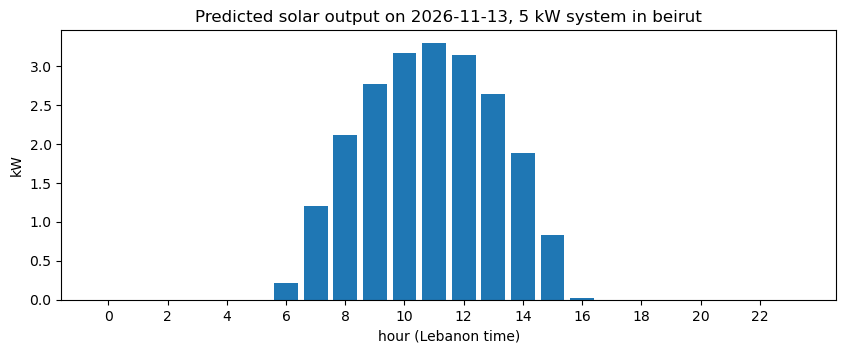

Expected energy tomorrow: 21.3 kWh
Best 3 hours: 10:00 to 13:00
Average day: run heavy appliances one at a time in the best hours.


In [ ]:
PLACE = "beirut"
LAT, LON = 33.896, 35.478
SYSTEM_KW = 5

TILT = 31
with open(os.path.join(DATA_DIR, "beirut.csv"), encoding="utf-8", errors="ignore") as f:
    for line in f:
        if line.startswith("Slope"):
            TILT = float(re.findall(r"-?\d+\.?\d*", line)[0])
print("panel tilt:", TILT)

r = requests.get("https://api.open-meteo.com/v1/forecast", timeout=30, params={
    "latitude": LAT, "longitude": LON, "timezone": "GMT", "forecast_days": 3,
    "hourly": "temperature_2m,wind_speed_10m,global_tilted_irradiance",
    "tilt": TILT, "azimuth": 0, "wind_speed_unit": "ms"})
r.raise_for_status()
js = r.json()
h = js["hourly"]

fc = pd.DataFrame({
    "time": pd.to_datetime(h["time"]).tz_localize("UTC") - pd.Timedelta(minutes=30),
    "G": h["global_tilted_irradiance"],
    "T2m": h["temperature_2m"],
    "WS10m": h["wind_speed_10m"],
}).dropna()
fc[["G", "T2m", "WS10m"]] = fc[["G", "T2m", "WS10m"]].astype(float)
fc["lat"], fc["lon"], fc["elevation"] = LAT, LON, js["elevation"]

fc["local"] = fc["time"].dt.tz_convert("Asia/Beirut")
tomorrow = (pd.Timestamp.now(tz="Asia/Beirut") + pd.Timedelta(days=1)).date()
fc = fc[fc["local"].dt.date == tomorrow].reset_index(drop=True)

solar_hour = (fc["time"].dt.hour + fc["time"].dt.minute / 60 + fc["lon"] / 15) % 24
doy = fc["time"].dt.dayofyear
fc["hour_sin"] = np.sin(2 * np.pi * solar_hour / 24)
fc["hour_cos"] = np.cos(2 * np.pi * solar_hour / 24)
fc["doy_sin"] = np.sin(2 * np.pi * doy / 365)
fc["doy_cos"] = np.cos(2 * np.pi * doy / 365)
decl = np.radians(23.44) * np.sin(2 * np.pi * (284 + doy) / 365)
hour_angle = np.radians(15 * (solar_hour - 12))
lat_r = np.radians(fc["lat"])
fc["sun_elev"] = np.degrees(np.arcsin(
    np.sin(lat_r) * np.sin(decl) + np.cos(lat_r) * np.cos(decl) * np.cos(hour_angle)))

X_fc = (fc[FEATURES].values - mu) / sd
fc["kW"] = np.clip(best.predict(X_fc), 0, 1) * SYSTEM_KW
fc.loc[fc["G"] <= 0, "kW"] = 0

total_kwh = fc["kW"].sum()
start = fc["kW"].rolling(3).sum().shift(-2).idxmax()
start_hour = fc["local"].dt.hour[start]
sun_hours = total_kwh / SYSTEM_KW

plt.figure(figsize=(10, 3.5))
plt.bar(fc["local"].dt.hour, fc["kW"])
plt.xlabel("hour (Lebanon time)")
plt.ylabel("kW")
plt.xticks(range(0, 24, 2))
plt.title(f"Predicted solar output on {tomorrow}, {SYSTEM_KW} kW system in {PLACE}")
plt.show()

print(f"Expected energy tomorrow: {total_kwh:.1f} kWh")
print(f"Best 3 hours: {start_hour}:00 to {start_hour + 3}:00")
if sun_hours >= 4.5:
    print("Strong day: run the washing machine and water heater in the best hours.")
elif sun_hours >= 2.5:
    print("Average day: run heavy appliances one at a time in the best hours.")
else:
    print("Weak day: save the battery and postpone heavy loads if you can.")

In [ ]:
import joblib

joblib.dump(
    {"model": best, "mu": mu, "sd": sd, "features": FEATURES, "tilt": TILT},
    "solar_model.joblib",
)
print("saved")